In [5]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate

# Imports from qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService


def grover_oracle(marked_states):
    """Build a Grover oracle for multiple marked states
[]
    Here we assume all input marked states have the same number of bits

    Parameters:
        marked_states (str or list): Marked states of oracle

    Returns:
        QuantumCircuit: Quantum circuit representing Grover oracle
    """
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    # Compute the number of qubits in circuit
    num_qubits = len(marked_states[0])

    qc = QuantumCircuit(num_qubits)
    # Mark each target state in the input list
    for target in marked_states:
        # Flip target bit-string to match Qiskit bit-ordering
        rev_target = target[::-1]
        # Find the indices of all the '0' elements in bit-string
        zero_inds = [
            ind
            for ind in range(num_qubits)
            if rev_target.startswith("0", ind)
        ]
        # Add a multi-controlled Z-gate with pre- and post-applied X-gates (open-controls)
        # where the target bit-string has a '0' entry
        if zero_inds:
            qc.x(zero_inds)
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)
        if zero_inds:
            qc.x(zero_inds)
    return qc

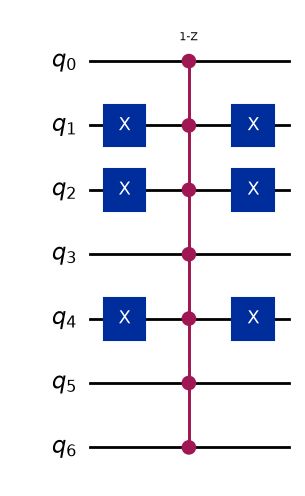

In [6]:
marked_states = ["1101001"]

oracle = grover_oracle(marked_states)

grover_op = grover_operator(oracle)

oracle.draw(output="mpl", style="iqp")

In [7]:
# Theoretical optimal number of Grover iterations
N = 2 ** grover_op.num_qubits
M = len(marked_states)

optimal_num_iterations = math.floor(
    math.pi / (4 * math.asin(math.sqrt(M / N)))
)

print("Theoretical optimal iterations:", optimal_num_iterations)

Theoretical optimal iterations: 8


C:\Users\compu\AppData\Local\Temp\ipykernel_4964\1605516653.py:10: DeprecationWarning: The method ``qiskit.circuit.library.standard_gates.x.MCXVChain.__new__()`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. It is recommended to use MCXGate and let HighLevelSynthesis choose the best synthesis method depending on the number of ancilla qubits available. If this specific synthesis method is required, one can specify it using the high-level-synthesis plugins `n_clean_m15` (using clean ancillas) or `n_dirty_i15` (using dirty ancillas) for MCX gates. Alternatively, one can use synth_mcx_n_dirty_i15 and synth_mcx_n_clean_m15 to construct the gate directly.
  mcx_gate = MCXVChain(num_ctrl_qubits=7)


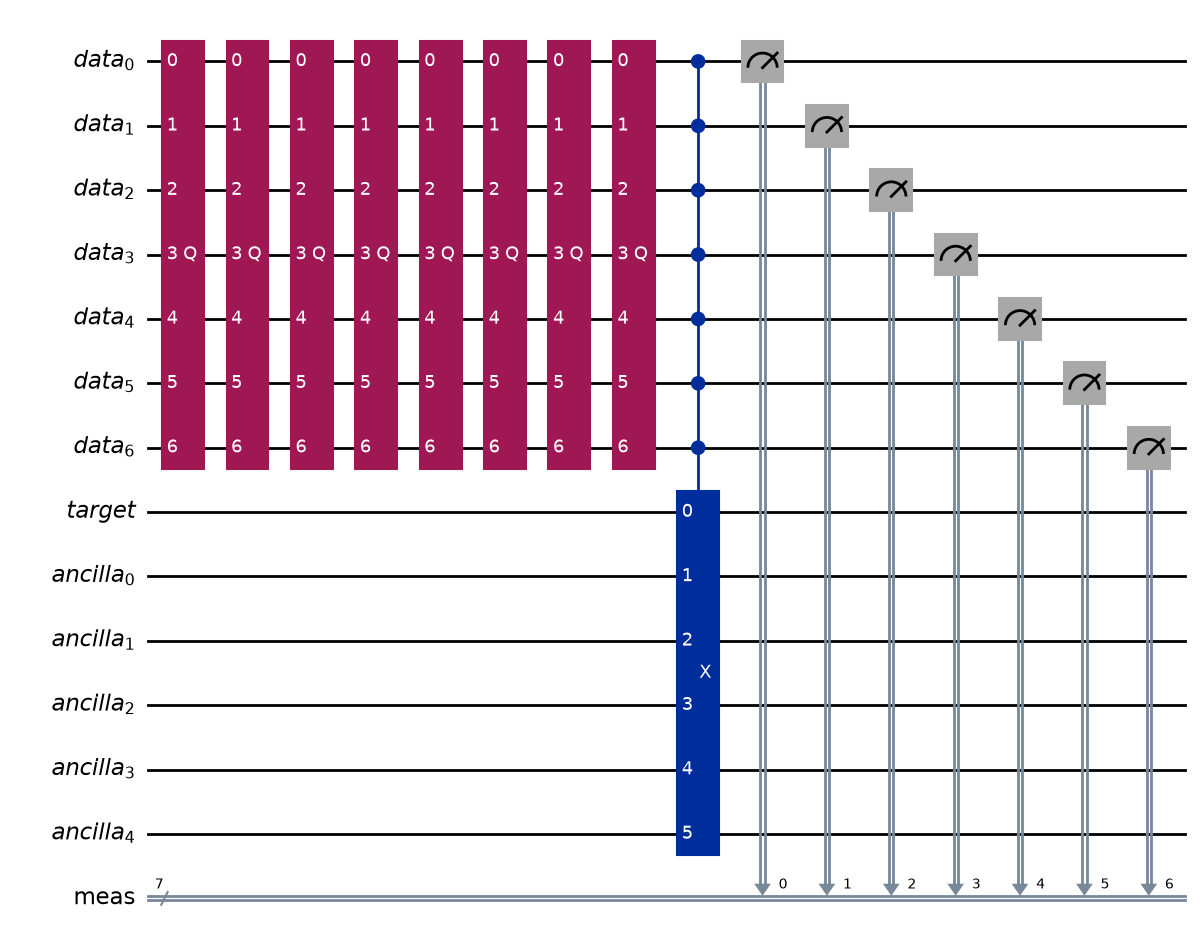

In [19]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import MCXVChain

qr_data = QuantumRegister(7, name='data')
qr_target = QuantumRegister(1, name='target')
# For a 7-control MCX v-chain, you need (num_controls - 2) ancillas -> 5 ancillas
qr_ancilla = QuantumRegister(5, name='ancilla')
cr = ClassicalRegister(7, name='meas')

mcx_gate = MCXVChain(num_ctrl_qubits=7) 

qc = QuantumCircuit(qr_data, qr_target, qr_ancilla, cr)

qc.compose(grover_op.power(optimal_num_iterations), inplace=True)

all_qubits = list(qr_data) + list(qr_target) + list(qr_ancilla)


qc.append(mcx_gate, all_qubits)

# Measure ONLY the 7 data qubits into your 7-bit classical register
qc.measure(qr_data, cr)
qc.draw(output="mpl", style="iqp")

In [12]:
service = QiskitRuntimeService()

backend = service.backend(name="ibm_fez")

In [ ]:
from qiskit import generate_preset_pass_manager, transpile
from qiskit_ibm_runtime import SamplerV2 as Sampler

shots = 10_000


pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)

sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XpXm" 

# Careful here: you're using compute minutes

In [14]:
job = sampler.run([isa_circuit])

In [15]:
result = job.result()
dist = result[0].data.meas.get_counts()

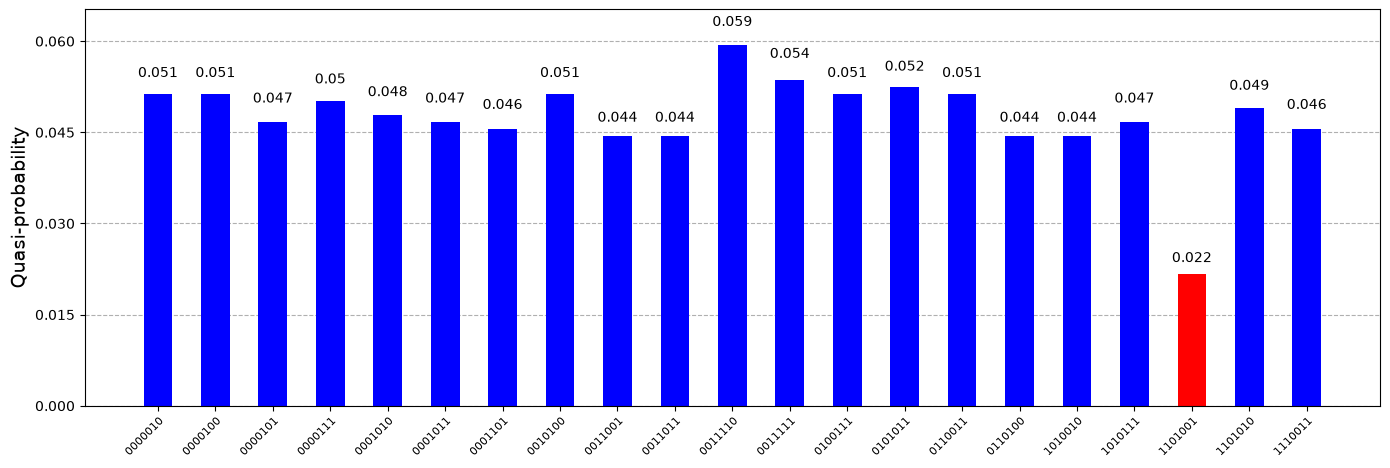

<Figure size 640x480 with 0 Axes>

In [16]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_distribution

# %matplotlib inline

# Bitstrings that must appear in red
red_states = marked_states

# Get the 20 most frequent outcomes
top_20 = dict(sorted(dist.items(), key=lambda item: item[1], reverse=True)[:20])

# Force all red states into the selection
for state in red_states:
    if state in dist:
        top_20[state] = dist[state]

# Plot the selected outcomes
fig = plot_distribution(top_20, figsize=(14, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in red_states:
        bar.set_facecolor('red')

ax.tick_params(axis='x', labelrotation=45, labelsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)

In [19]:
from pathlib import Path

output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Plot the selected outcomes
fig = plot_distribution(dist, figsize=(200, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in marked_states:
        bar.set_facecolor('red')

fig.savefig(output_dir / "dist_1.png", dpi=300, bbox_inches="tight")